Acceptance rate = 0.7805272727272726
<x>   = -0.3549 ± 0.0056
<x^2> = 0.6234 ± 0.0074


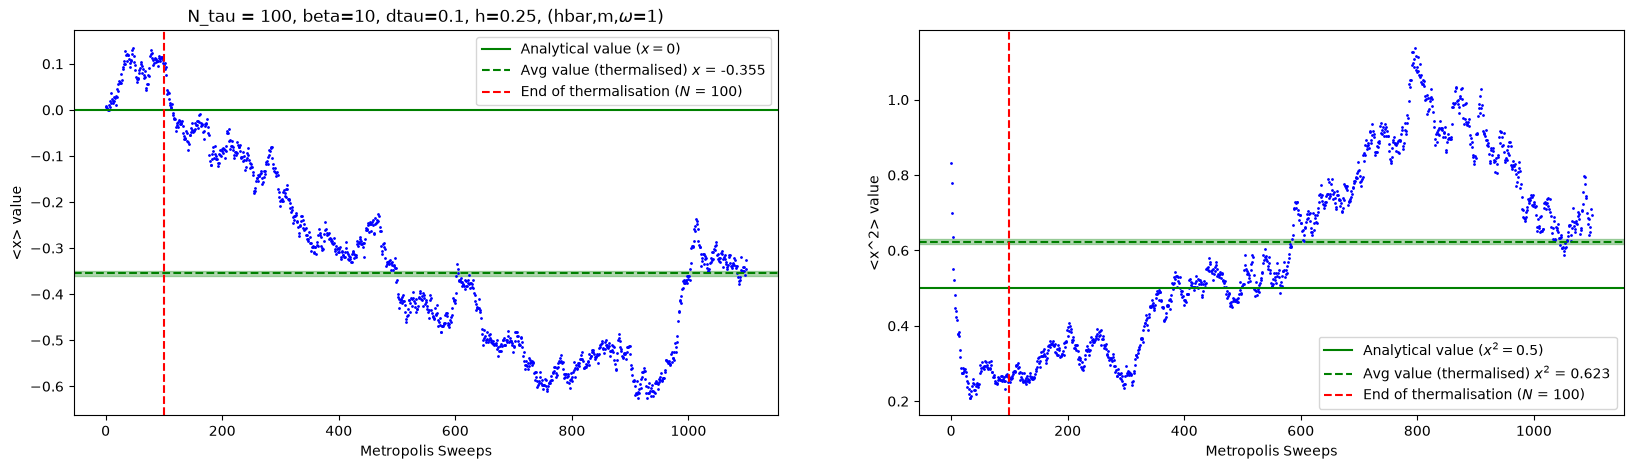

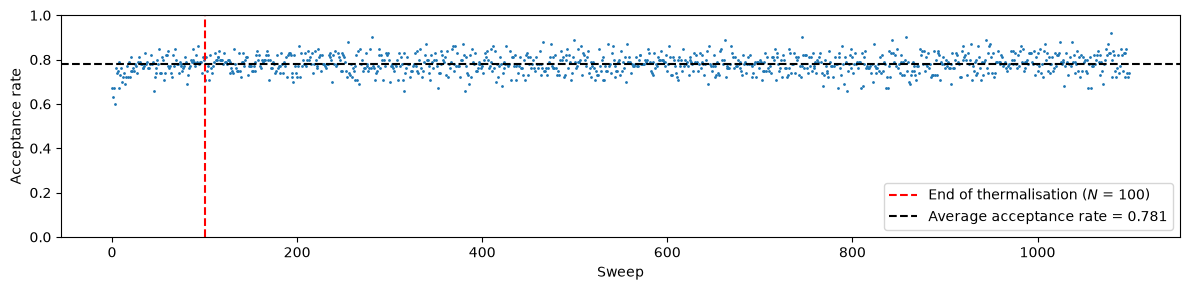

In [2]:
import numpy as np
import matplotlib.pyplot as plt

#keeping the seed the same each time
#np.random.seed(150) 

#Define Parameters
h = 0.25 #step size
m = omega = hbar = 1
N_tau = 100 #size of the lattice
path = np.random.randn(N_tau)
beta = 10
delta_tau = beta / N_tau

#length of path is N_tau
def local_action(path, tau, x, delta_tau, m, omega):
    N_tau = len(path)

    # Every site needs two neighbours but the array only has indicies from
    # 0 to N_tau-1, so the two ends would run off the array
    # the %N wraps the values around so the periodic boundary conditions are satisfied
    left = path[(tau - 1) % N_tau]
    right = path[(tau + 1) % N_tau] #double check modulo

    kinetic = (m / (2 * delta_tau) 
               * ((x - left)**2 + (right - x)**2))

    potential = (delta_tau
        * 0.5 * m * (omega**2) * (x**2))
    
    return kinetic + potential

#for every lattice site:
    #choose a site               (1)
    #propose a new x             (2)
    #calculate ΔS                (3)
    #decide whether to accept    (4)

def metropolis_sweep(path, delta_tau):
    acceptance = 0
    N_tau = len(path) #define number of elements in time lattice

    for i in range(N_tau):
        tau = np.random.randint(N_tau) #(1), choosing random site to start at
        j = np.random.uniform(-h,h) #generating the amount to change the site to

        x_old = path[tau] #defining old position in array
        x_new = x_old + j #(2)

        S_old = local_action(path, tau, x_old, delta_tau, m, omega)
        S_new = local_action(path, tau, x_new, delta_tau, m, omega)

        dS = S_new - S_old #(3)
        if dS <= 0 or np.random.rand() < np.exp(-dS): #(4)
            path[tau] = x_new
            acceptance += 1
                # New values that lower the action are always accepted
                # While those that would increase the action are 
                # accepted with probablity exp(-delta_S)
    acc_rate = acceptance/N_tau

    return path, acc_rate

def naive_error(a):
    return a.std(ddof=1)/np.sqrt(len(a))

N_therm = 100 #how many of the first sweeps are discarded
N_sweeps = 1000 #how many passes are repeated

x = []
x_2 = []
total_acc_rate = []

for i in range(N_therm + N_sweeps):
    total_path, acc_rate = metropolis_sweep(path, delta_tau)
    x.append(np.mean(total_path))
    x_2.append(np.mean(total_path**2))
    total_acc_rate.append(acc_rate)

# Slicing to get rid of first N_therm sweeps for thermalisation
#x = np.array(x)
#x_2 = np.array(x_2)
x_thermalised = np.array(x[N_therm:])
x_2_thermalised = np.array(x_2[N_therm:])
total_acc_rate = np.array(total_acc_rate)

print(f"Acceptance rate = {np.mean(total_acc_rate)}")
print(f"<x>   = {np.mean(x_thermalised):.4f} ± {naive_error(x_thermalised):.4f}")
print(f"<x^2> = {np.mean(x_2_thermalised):.4f} ± {naive_error(x_2_thermalised):.4f}")

# Expectation values vs. sweeps
sweeps = np.arange(len(x))
fig, ax = plt.subplots(1, 2, figsize=(20,5))
ax[0].plot(sweeps, x, 'o', color="blue", markersize=1)
ax[0].set_xlabel("Metropolis Sweeps")
ax[0].set_ylabel("<x> value")
#ax[0].set_ylim(-0.25, 0.25)
ax[0].axhline(y=0, color='g', linestyle='-', label = f"Analytical value ($x=0$)")
ax[0].axhline(y=np.mean(x_thermalised), color='g', linestyle='--', label = f"Avg value (thermalised) $x$ = {np.round(np.mean(x_thermalised), decimals=3)}")
ax[0].axvline(N_therm, color='r', linestyle='--', label = f"End of thermalisation ($N$ = {N_therm})")
ax[0].set_title(rf"N_tau = {N_tau}, beta={beta}, dtau={delta_tau}, h={h}, (hbar,m,$\omega$={m})")
ax[0].legend()

ax[1].plot(sweeps, x_2, 'o', color="blue", markersize=1)
ax[1].set_xlabel("Metropolis Sweeps")
ax[1].set_ylabel("<x^2> value")
#ax[1].set_ylim(0.4, 0.6)
ax[1].axhline(y=0.5, color='g', linestyle='-', label = f"Analytical value ($x^2=0.5$)")
ax[1].axhline(y=np.mean(x_2_thermalised), color='g', linestyle='--', label = f"Avg value (thermalised) $x^2$ = {np.round(np.mean(x_2_thermalised), decimals=3)}")
ax[1].axvline(N_therm, color='r', linestyle='--', label = f"End of thermalisation ($N$ = {N_therm})")
ax[1].legend()

# Acceptance rate
plt.figure(figsize=(12,3))
plt.plot(total_acc_rate, '.', markersize=2)
plt.axvline(N_therm, color='red', linestyle='--', label = f"End of thermalisation ($N$ = {N_therm})")
plt.axhline(np.mean(total_acc_rate), linestyle='--', color='black', label=f"Average acceptance rate = {np.round(np.mean(total_acc_rate), decimals=3)}")
plt.ylim(0,1)
plt.xlabel("Sweep")
plt.ylabel("Acceptance rate")
plt.legend()

x_mean, x_error = np.mean(x_thermalised), naive_error(x_thermalised)
x_2_mean, x_2_error = np.mean(x_2_thermalised), naive_error(x_2_thermalised)

ax[0].axhspan(x_mean - x_error, x_mean + x_error, color="green", alpha=0.3)
ax[1].axhspan(x_2_mean - x_2_error, x_2_mean + x_2_error, color="green", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
def integrated_auto_correlation(a, c=5):

    a = np.asarray(a) - np.mean(a) #ensuring series is centered (mean = 0)

    N = len(a)
    var = np.mean(a**2)
    max_lag = N//2

    #C(L) is the correlation between two measurements that are L sweeps apart
    #must be computed one at a time
    C = np.zeros(max_lag)

    # a[:N-lag] is the series with the last entry chopped off
    # a[lag:] is the series with the first entry chopped off]
    for lag in range(max_lag):
        C[lag] = np.array([np.mean(a[:N-lag]*a[lag:]) / var])

    A = np.cumsum(C[1:])

    tau_int = 1/2 + A

    #we will use Sokal's cutoff criterion to ensure that once the error reduces into noise we stop itnegrating 
    for W in range(1, len(A) + 1):
        tau_int = tau_int[W-1]
        if W >= c*tau_int:
            return tau_int, W, C

    #what to return if the window never closed due to not enough sweeps 
    return tau_int[-1], len(tau_int), C

x_true_error = 